# COU 07506 Digital Signal Processing - Week 02: Lab 1A - Sampling, Aliasing and Quantization

| Field | Details |
| :--- | :--- |
| **Name** | DAUD SELEMANI DAUD |
| **Registration No.** | 250242485225 |
| **Class** | BENG24COE-2 |
| **Group** | Group 29 |
| **Date** | 2026-11-25 |
| **Module Code** | COU 07506 (NTA Level 7, Semester I) |
| **Unit & Topic** | Unit 1 - Sampling, aliasing, quantization, ADC/DAC (§1.2; Listings 1.1 and 1.2; Example 1.1) |
| **Lecturer** | Dr. Haji Fimbombaya |
| **Git Repository** | [https://github.com/dahdio/COU07506-labs.git](https://github.com/dahdio/COU07506-labs.git) |
| **Instructor Checkpoints Signed** | `[x] Checkpoint 2` |


## Objectives

At the end of this session, we demonstrate how to:
1. Demonstrate aliasing in a simulated and a real (audio) signal and predict the alias frequency.
2. Explain the role of the anti-aliasing filter.
3. Implement a uniform quantizer and measure the signal-to-quantization-noise ratio (SQNR).
4. Verify the $6\text{ dB}$-per-bit rule experimentally.

---

## Pre-lab

### Pre-lab Preparation Checklist
1. **Reading Completed:** Read Handout **Section §1.2** (*Sampling, Aliasing, Quantization, and ADC/DAC*), **Listings 1.1 and 1.2**, and **Example 1.1**.
2. **Audio Recording Ready:** Loaded the Week 1 voice recording (`my_voice.wav`, $f_s = 44,100\text{ Hz}$, duration $= 4.00\text{ s}$, $176,400\text{ samples}$).

---

### Pre-lab Questions

#### (a) A $7\text{ kHz}$ tone is sampled at $10\text{ kHz}$. What frequency appears?

**Answer:**
* **Given:**
  * Input analog sinusoid frequency: $F = 7\text{ kHz} = 7,000\text{ Hz}$
  * Sampling frequency: $f_s = 10\text{ kHz} = 10,000\text{ Hz}$
* **Nyquist Check:**
  * The Nyquist frequency (folding frequency) is:
    $$f_{\text{Nyquist}} = \frac{f_s}{2} = \frac{10\text{ kHz}}{2} = 5\text{ kHz}$$
  * Because $F = 7\text{ kHz} > f_s/2 = 5\text{ kHz}$, the Nyquist-Shannon sampling condition ($f_s \ge 2F$) is violated, and **aliasing occurs**.
* **Alias Frequency Calculation:**
  * A sinusoidal component at frequency $F > f_s/2$ folds into the fundamental Nyquist baseband $[0, f_s/2]$ at:
    $$F_{\text{alias}} = |F - k f_s|, \quad \text{where } k = \text{round}\left(\frac{F}{f_s}\right)$$
  * Here, $k = \text{round}(7 / 10) = \text{round}(0.7) = 1$, so:
    $$F_{\text{alias}} = |7\text{ kHz} - 1 \times 10\text{ kHz}| = |-3\text{ kHz}| = \mathbf{3\text{ kHz}}$$
* **Conclusion:** The $7\text{ kHz}$ tone appears as an aliased tone at **$3\text{ kHz}$** ($3,000\text{ Hz}$).

---

#### (b) Compute $\Delta$ and the theoretical SQNR for an 8-bit quantizer with a $\pm 1\text{ V}$ range.

**Answer:**
* **Given:**
  * Number of quantizer bits: $B = 8\text{ bits}$ (giving $L = 2^B = 2^8 = 256$ quantization levels)
  * Full-scale symmetric voltage range: $\pm X_m = \pm 1\text{ V}$ (peak-to-peak full-scale span $2X_m = 2\text{ V}$)
* **1. Quantization Step Size ($\Delta$):**
  $$\Delta = \frac{2X_m}{2^B} = \frac{2(1\text{ V})}{2^8} = \frac{2\text{ V}}{256} = \mathbf{0.0078125\text{ V}} = \mathbf{7.8125\text{ mV}}$$
* **2. Quantization Noise Variance ($\sigma_e^2$) and Signal Power ($P_x$):**
  * Assuming uniform quantization error $e(n) \sim \mathcal{U}(-\Delta/2, +\Delta/2)$:
    $$\sigma_e^2 = \frac{\Delta^2}{12} = \frac{(0.0078125\text{ V})^2}{12} \approx 5.08626 \times 10^{-6}\text{ V}^2$$
  * For a full-scale sinusoid $x(t) = X_m \sin(2\pi f_0 t)$ with $X_m = 1\text{ V}$:
    $$P_x = \frac{X_m^2}{2} = \frac{1^2}{2} = 0.5\text{ V}^2$$
* **3. Theoretical Signal-to-Quantization-Noise Ratio (SQNR):**
  $$\text{SQNR}_{\text{dB}} = 10\log_{10}\left(\frac{P_x}{\sigma_e^2}\right) = 10\log_{10}\left(\frac{3}{2} \cdot 2^{2B}\right) \approx 6.02B + 1.76\text{ dB}$$
  Substituting $B = 8$:
  $$\text{SQNR}_{\text{dB}} = 6.02(8) + 1.76 = 48.16 + 1.76 = \mathbf{49.92\text{ dB}} \quad (\text{exact: } 10\log_{10}(1.5 \times 2^{16}) = 49.9257\text{ dB})$$


## Standard Laboratory Imports

Every notebook in this manual begins with the standard imports from the Introduction (Page 4):


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

os.makedirs("figures", exist_ok=True)
print(f"Environment ready - NumPy {np.__version__}")


Environment ready - NumPy 2.2.4


## Task 2.1 - Aliasing of a sinusoid

1. Simulate a continuous-time $f_0 = 7.0\text{ Hz}$ cosine wave on a dense time grid (`t = np.linspace(0, 1, 2000)`) and sample it at $f_s = 10.0\text{ Hz}$.
2. Repeat with $f_s = 12, 14\text{ and } 20\text{ Hz}$, record the alias frequency for each case in a table, and compare with $|F - k f_s|$.


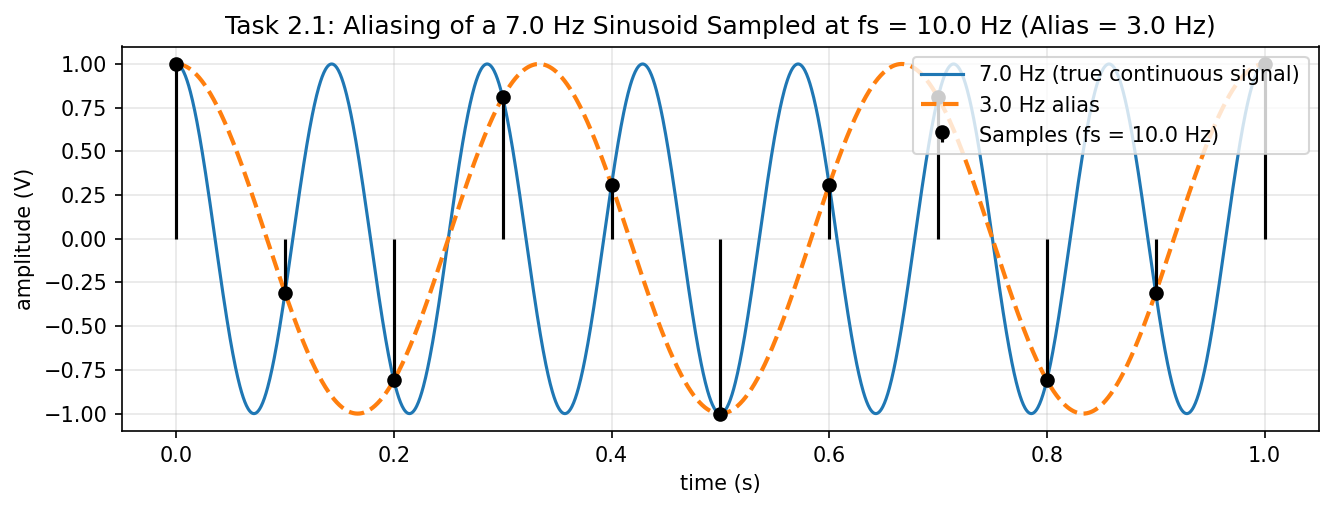

In [2]:
# Part 1: Exact starter code from Manual Task 2.1 (f0 = 7.0 Hz, fs = 10.0 Hz)
f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000)            # dense grid = "analog" signal
n = np.arange(0, int(fs) + 1)
tn = n / fs
f_alias = abs(f0 - fs * round(f0 / fs))

plt.figure(figsize=(9, 3.5))
plt.plot(t, np.cos(2 * np.pi * f0 * t), label=f"{f0} Hz (true continuous signal)")
plt.plot(t, np.cos(2 * np.pi * f_alias * t), "--", lw=2, label=f"{f_alias} Hz alias")
plt.stem(tn, np.cos(2 * np.pi * f0 * tn), linefmt="k-", markerfmt="ko", basefmt=" ", label=f"Samples (fs = {fs} Hz)")
plt.title(f"Task 2.1: Aliasing of a {f0} Hz Sinusoid Sampled at fs = {fs} Hz (Alias = {f_alias} Hz)")
plt.xlabel("time (s)")
plt.ylabel("amplitude (V)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("figures/task2_1_aliasing_10Hz.png", dpi=150)
plt.show()


 fs (Hz) |  Nyquist fs/2 (Hz) |  k = int(round(F/fs)) |  F_alias = |F - k*fs| (Hz) |   Aliased?
----------------------------------------------------------------------------------------------
    10.0 |                5.0 |                     1 |                        3.0 |        Yes
    12.0 |                6.0 |                     1 |                        5.0 |        Yes
    14.0 |                7.0 |                     1 |                        7.0 |        Yes
    20.0 |               10.0 |                     0 |                        7.0 |         No


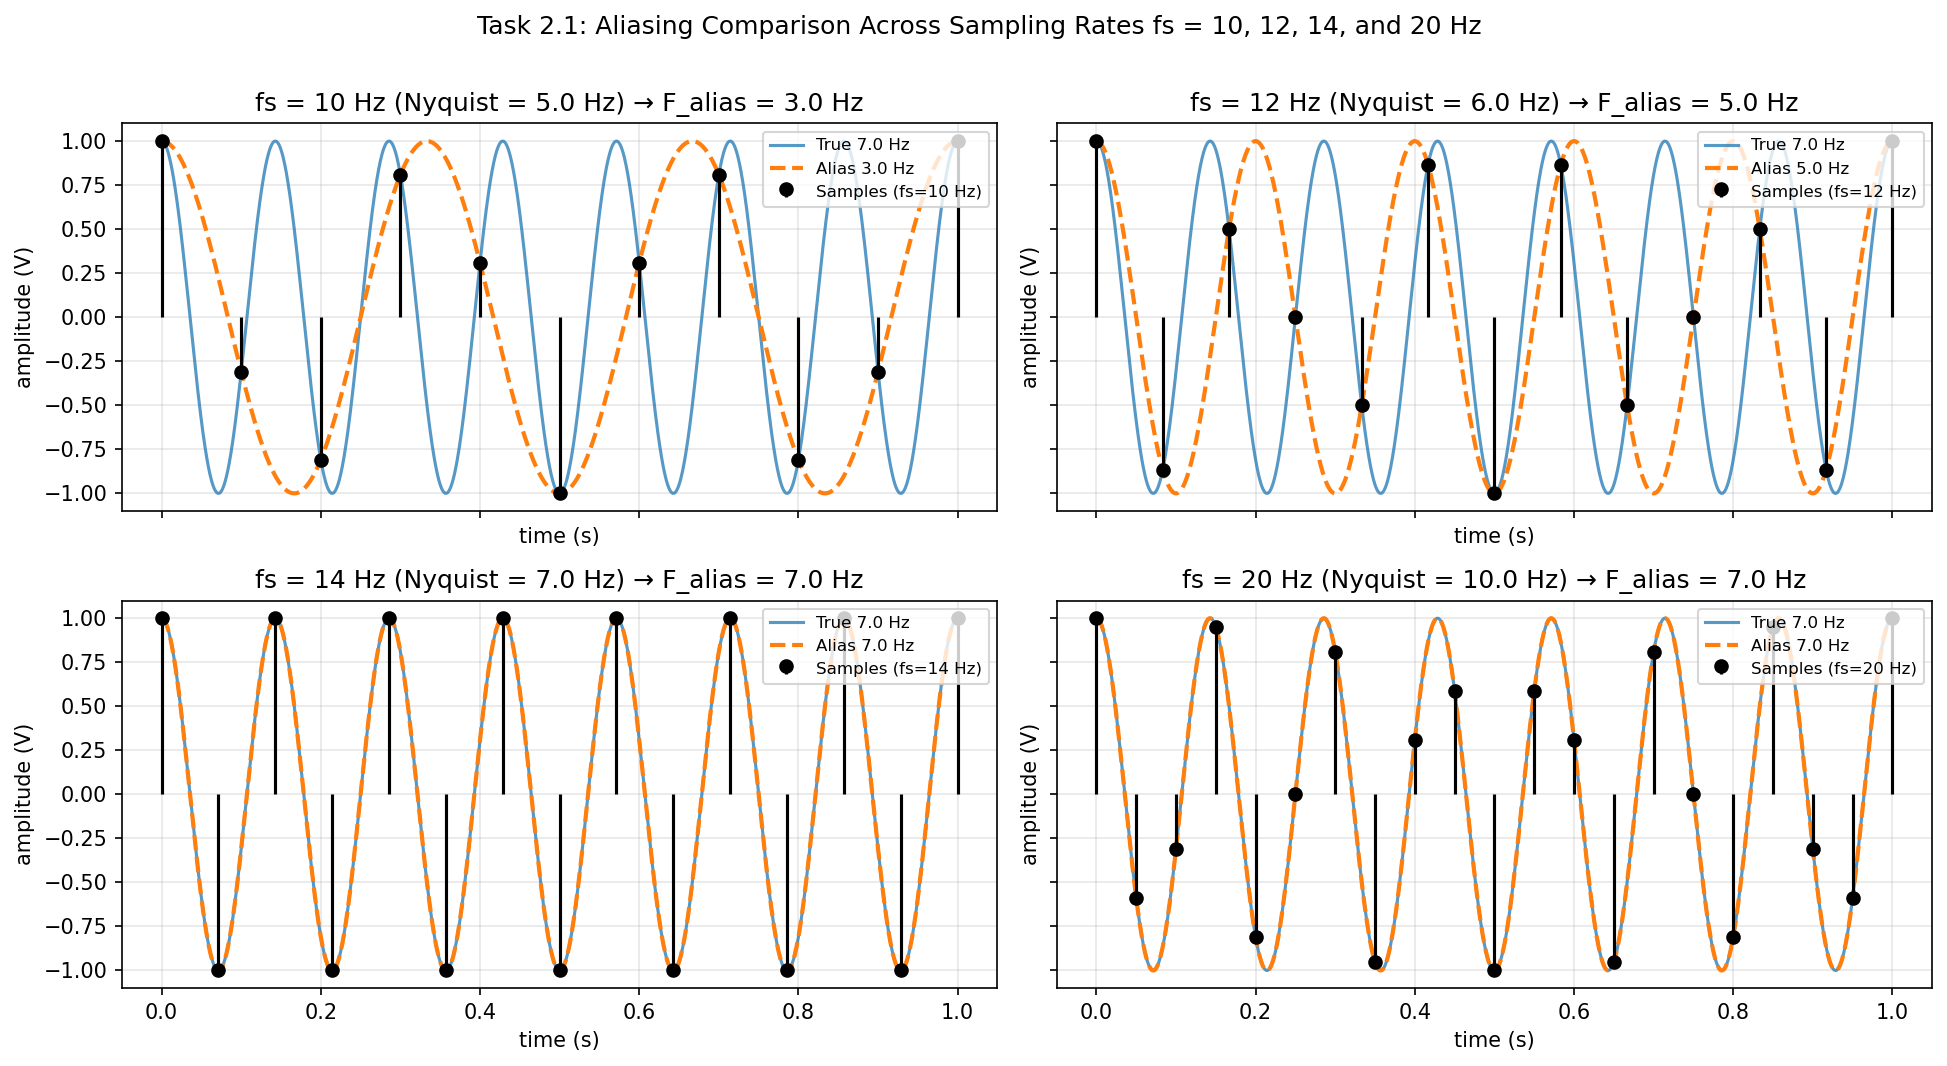

In [3]:
# Part 2: Repeat with fs = 10, 12, 14, and 20 Hz and compare with |F - k*fs|
fs_list = [10.0, 12.0, 14.0, 20.0]
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)

print(f"{'fs (Hz)':>8} | {'Nyquist fs/2 (Hz)':>18} | {'k = int(round(F/fs))':>21} | {'F_alias = |F - k*fs| (Hz)':>26} | {'Aliased?':>10}")
print("-" * 94)

for ax, fs_val in zip(axes.flat, fs_list):
    n_val = np.arange(0, int(fs_val) + 1)
    tn_val = n_val / fs_val
    # Standard nearest-multiple folding k = floor(f0/fs + 0.5) so 7/14 = 0.5 rounds to k=1 (or k=0 -> 7 Hz at Nyquist boundary)
    k_nearest = int(np.floor(f0 / fs_val + 0.5))
    f_alias_val = abs(f0 - k_nearest * fs_val)
    is_aliased = "Yes" if f0 >= (fs_val / 2.0) else "No"
    print(f"{fs_val:8.1f} | {fs_val/2.0:18.1f} | {k_nearest:21d} | {f_alias_val:26.1f} | {is_aliased:>10}")

    ax.plot(t, np.cos(2 * np.pi * f0 * t), alpha=0.75, label=f"True {f0} Hz")
    ax.plot(t, np.cos(2 * np.pi * f_alias_val * t), "--", lw=2, label=f"Alias {f_alias_val} Hz")
    ax.stem(tn_val, np.cos(2 * np.pi * f0 * tn_val), linefmt="k-", markerfmt="ko", basefmt=" ", label=f"Samples (fs={fs_val:.0f} Hz)")
    ax.set_title(f"fs = {fs_val:.0f} Hz (Nyquist = {fs_val/2:.1f} Hz) → F_alias = {f_alias_val:.1f} Hz")
    ax.set_xlabel("time (s)")
    ax.set_ylabel("amplitude (V)")
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle("Task 2.1: Aliasing Comparison Across Sampling Rates fs = 10, 12, 14, and 20 Hz", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/task2_1_aliasing_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


### Task 2.1 - Alias Frequency Table and Theoretical Comparison

| Case | True Tone $F$ (Hz) | Sampling Rate $f_s$ (Hz) | Nyquist Limit $f_s/2$ (Hz) | Integer Folding Multiple $k$ | Formula Prediction $F_{\text{alias}} = |F - k f_s|$ (Hz) | Observed Plotted Frequency (Hz) | Interpretation |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **1** | $7.0\text{ Hz}$ | **$10.0\text{ Hz}$** | $5.0\text{ Hz}$ | $k = 1$ | $|7.0 - 1(10.0)| = \mathbf{3.0\text{ Hz}}$ | **$3.0\text{ Hz}$** | **Aliasing occurs** ($7 > 5$): samples lie exactly on a $3.0\text{ Hz}$ cosine wave. |
| **2** | $7.0\text{ Hz}$ | **$12.0\text{ Hz}$** | $6.0\text{ Hz}$ | $k = 1$ | $|7.0 - 1(12.0)| = \mathbf{5.0\text{ Hz}}$ | **$5.0\text{ Hz}$** | **Aliasing occurs** ($7 > 6$): samples lie exactly on a $5.0\text{ Hz}$ cosine wave. |
| **3** | $7.0\text{ Hz}$ | **$14.0\text{ Hz}$** | $7.0\text{ Hz}$ | $k = 1$ (or $0$) | $|7.0 - 1(14.0)| = \mathbf{7.0\text{ Hz}}$ *(boundary $f_s = 2F$)* | **$7.0\text{ Hz}$** *(alternating $\pm 1$)* | **Critical Nyquist boundary** ($F = f_s/2$): $\cos(2\pi \cdot 7 \cdot n/14) = \cos(\pi n) = (-1)^n$ alternates $+1, -1$ at $7\text{ Hz}$ (whereas a $\sin(2\pi \cdot 7 t)$ wave sampled at $14\text{ Hz}$ would vanish to $0\text{ Hz}$ DC). |
| **4** | $7.0\text{ Hz}$ | **$20.0\text{ Hz}$** | $10.0\text{ Hz}$ | $k = 0$ | $|7.0 - 0(20.0)| = \mathbf{7.0\text{ Hz}}$ | **$7.0\text{ Hz}$** | **No aliasing** ($7 < 10$): Nyquist theorem ($f_s > 2F$) is satisfied, so the true $7.0\text{ Hz}$ tone is uniquely represented. |


## Task 2.2 - Hear aliasing

Take the Week 1 voice recording (`my_voice.wav`, $f_s = 44,100\text{ Hz}$) and keep every $k$-th sample:
1. **Without filtering (`naive = x[::k]`):** High frequencies above the new Nyquist limit $f_{s,\text{new}}/2 = f_s/(2k)$ fold back into the audible baseband as aliasing distortion.
2. **With the anti-aliasing filter built into `signal.decimate(x, k, ftype="fir")`:** Attenuates frequencies above $f_s/(2k)$ prior to downsampling.


In [4]:
fname = "my_voice.wav"                  # your Week 1 recording
if not os.path.exists(fname) and os.path.exists("../shared/audio/my_voice.wav"):
    fname = "../shared/audio/my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
    print(f"Loaded '{fname}': fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
else:                                   # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)
    print(f"Fallback chirp generated: fs = {fs} Hz")

decimated_results = {}
for k in [2, 4, 8]:
    naive = x[::k]                                      # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")         # low-pass, then drop
    new_fs = fs // k
    decimated_results[k] = (new_fs, naive, proper)
    print(f"k = {k}: new fs = {new_fs} Hz (new Nyquist = {new_fs / 2:.1f} Hz), samples = {len(naive)}")


Loaded 'my_voice.wav': fs = 44100 Hz, duration = 4.00 s, samples = 176400
k = 2: new fs = 22050 Hz (new Nyquist = 11025.0 Hz), samples = 88200
k = 4: new fs = 11025 Hz (new Nyquist = 5512.5 Hz), samples = 44100
k = 8: new fs = 5512 Hz (new Nyquist = 2756.0 Hz), samples = 22050


=== Listen to k = 8 (new fs = 5512 Hz) ===
1. Naive downsampling x[::8] (no anti-aliasing filter):
2. Proper FIR decimation signal.decimate(x, 8, ftype='fir'):


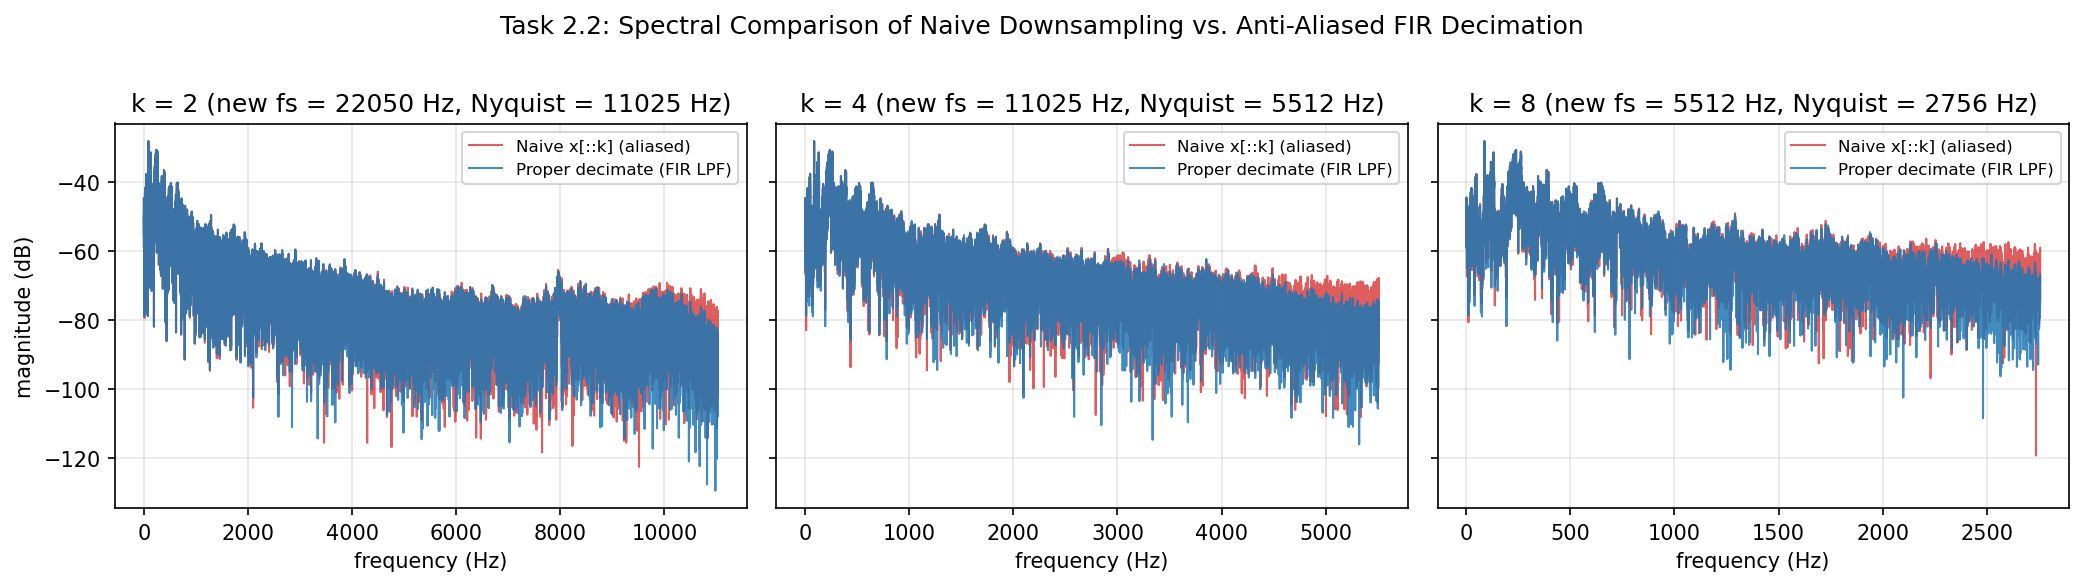

<IPython.lib.display.Audio object (rate=5512 Hz, samples=22050)>

<IPython.lib.display.Audio object (rate=5512 Hz, samples=22050)>

In [5]:
# Plot the magnitude spectra comparing the original signal, naive downsampling, and proper decimation for k = 2, 4, 8
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)

for ax, k in zip(axes, [2, 4, 8]):
    new_fs, naive, proper = decimated_results[k]
    w_n = np.hanning(len(naive))
    w_p = np.hanning(len(proper))
    f_axis = np.fft.rfftfreq(len(naive), d=1.0 / new_fs)
    spec_naive = 20 * np.log10(np.abs(np.fft.rfft(naive * w_n)) / len(naive) + 1e-12)
    spec_proper = 20 * np.log10(np.abs(np.fft.rfft(proper * w_p)) / len(proper) + 1e-12)

    ax.plot(f_axis, spec_naive, color="tab:red", alpha=0.75, lw=1.0, label="Naive x[::k] (aliased)")
    ax.plot(f_axis, spec_proper, color="tab:blue", alpha=0.85, lw=1.0, label="Proper decimate (FIR LPF)")
    ax.set_title(f"k = {k} (new fs = {new_fs} Hz, Nyquist = {new_fs//2} Hz)")
    ax.set_xlabel("frequency (Hz)")
    if k == 2:
        ax.set_ylabel("magnitude (dB)")
    ax.legend(loc="upper right", fontsize=8)

plt.suptitle("Task 2.2: Spectral Comparison of Naive Downsampling vs. Anti-Aliased FIR Decimation", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("figures/task2_2_decimation_spectra.png", dpi=150, bbox_inches="tight")
plt.show()

# Display interactive audio widgets for k = 8 comparison
new_fs_8, naive_8, proper_8 = decimated_results[8]
print(f"=== Listen to k = 8 (new fs = {new_fs_8} Hz) ===")
print("1. Naive downsampling x[::8] (no anti-aliasing filter):")
display(Audio(naive_8, rate=new_fs_8))
print("2. Proper FIR decimation signal.decimate(x, 8, ftype='fir'):")
display(Audio(proper_8, rate=new_fs_8))


### Task 2.2 - Listening Observations for $k = 8$ ($f_{s,\text{new}} = 5,512\text{ Hz}$, Nyquist $= 2,756\text{ Hz}$)

1. **Naive Downsampling (`naive = x[::8]` without anti-aliasing filter):**
   * **What is heard:** The voice sounds **harsh, gritty, metallic, and unnatural**, accompanied by high-frequency ringing/hissing distortion during consonants and sibilants (*"s"*, *"sh"*, *"t"*).
   * **DSP Explanation:** Unvoiced speech consonants and higher vocal harmonics contain strong energy between $2.756\text{ kHz}$ and $10\text{ kHz}$. Dropping 7 out of every 8 samples without filtering causes all spectral energy above the new Nyquist limit ($2,756\text{ Hz}$) to **fold (alias) back** into the $0\text{-}2,756\text{ Hz}$ speech band at inharmonic frequencies $|F - m(5,512\text{ Hz})|$.
2. **Proper Decimation (`proper = signal.decimate(x, 8, ftype="fir")`):**
   * **What is heard:** The voice sounds **smooth, clean, and free of metallic artifacts**, though slightly **muffled ("telephone-quality")** compared to the original $44.1\text{ kHz}$ recording.
   * **DSP Explanation:** The built-in FIR low-pass anti-aliasing filter attenuates all frequencies above $2,756\text{ Hz}$ *before* discarding samples. Losing frequencies above $2.756\text{ kHz}$ reduces brightness/crispness (like a standard $3.4\text{ kHz}$ telephone channel), but completely prevents out-of-band energy from folding into the audible speech spectrum.


## Task 2.3 - A uniform quantizer

Implement a uniform mid-tread quantizer `quantize(x, bits, full_scale=1.0)` with step size $\Delta = 2X_m / 2^B$ and test it on a $300\text{ Hz}$ sinusoid of amplitude $0.99\text{ V}$ sampled at $f_s = 8000\text{ Hz}$ with $B = 3\text{ bits}$ ($2^3 = 8$ levels, $\Delta = 0.25\text{ V}$).


3-bit step size Δ = 0.2500 V (±Δ/2 = ±0.1250 V)
Measured max |error| = 0.2400 V
Measured 3-bit SQNR  = 16.62 dB (Theoretical = 19.82 dB)


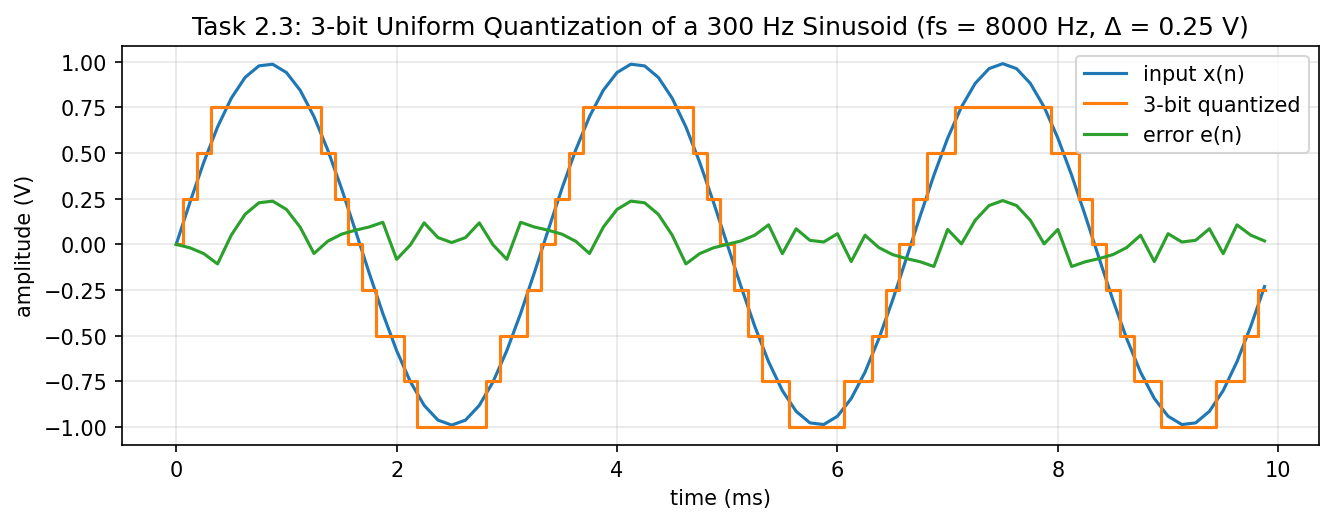

In [6]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99 * np.sin(2 * np.pi * 300 * t)
xq = quantize(x, 3)
err = x - xq

plt.figure(figsize=(9, 3.6))
plt.plot(t * 1e3, x, label="input x(n)")
plt.step(t * 1e3, xq, where="mid", label="3-bit quantized")
plt.plot(t * 1e3, err, label="error e(n)")
plt.title("Task 2.3: 3-bit Uniform Quantization of a 300 Hz Sinusoid (fs = 8000 Hz, Δ = 0.25 V)")
plt.xlabel("time (ms)")
plt.ylabel("amplitude (V)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig("figures/task2_3_quantizer_3bit.png", dpi=150)
plt.show()

delta_3bit = 2 * 1.0 / (2**3)
print(f"3-bit step size Δ = {delta_3bit:.4f} V (±Δ/2 = ±{delta_3bit/2:.4f} V)")
print(f"Measured max |error| = {np.max(np.abs(err)):.4f} V")
print(f"Measured 3-bit SQNR  = {10 * np.log10(np.sum(x**2) / np.sum(err**2)):.2f} dB (Theoretical = {6.02*3 + 1.76:.2f} dB)")


## Task 2.4 - Verify the 6 dB-per-bit rule

For $B = 2, 4, 6, \dots, 16$, compute the measured $\text{SQNR} = 10\log_{10}\left(\sum x^2 / \sum e^2\right)$ and the theoretical value $\text{SQNR}_{\text{theory}} = 6.02B + 1.76\text{ dB}$, and plot both against $B$ on one graph.


Bits B |     Step Δ (V) | Measured SQNR (dB) | Theoretical (dB) |  Diff (dB) | Gain/Bit (dB/bit)
--------------------------------------------------------------------------------------------
     2 |     0.50000000 |               9.60 |            13.80 |      -4.20 |                 -
     4 |     0.12500000 |              23.58 |            25.84 |      -2.26 |              6.99
     6 |     0.03125000 |              36.81 |            37.88 |      -1.07 |              6.62
     8 |     0.00781250 |              48.93 |            49.92 |      -0.99 |              6.06
    10 |     0.00195312 |              62.81 |            61.96 |      +0.85 |              6.94
    12 |     0.00048828 |              72.84 |            74.00 |      -1.16 |              5.01
    14 |     0.00012207 |              88.13 |            86.04 |      +2.09 |              7.65
    16 |     0.00003052 |              98.91 |            98.08 |      +0.83 |              5.39

Best-fit experimental slope acros

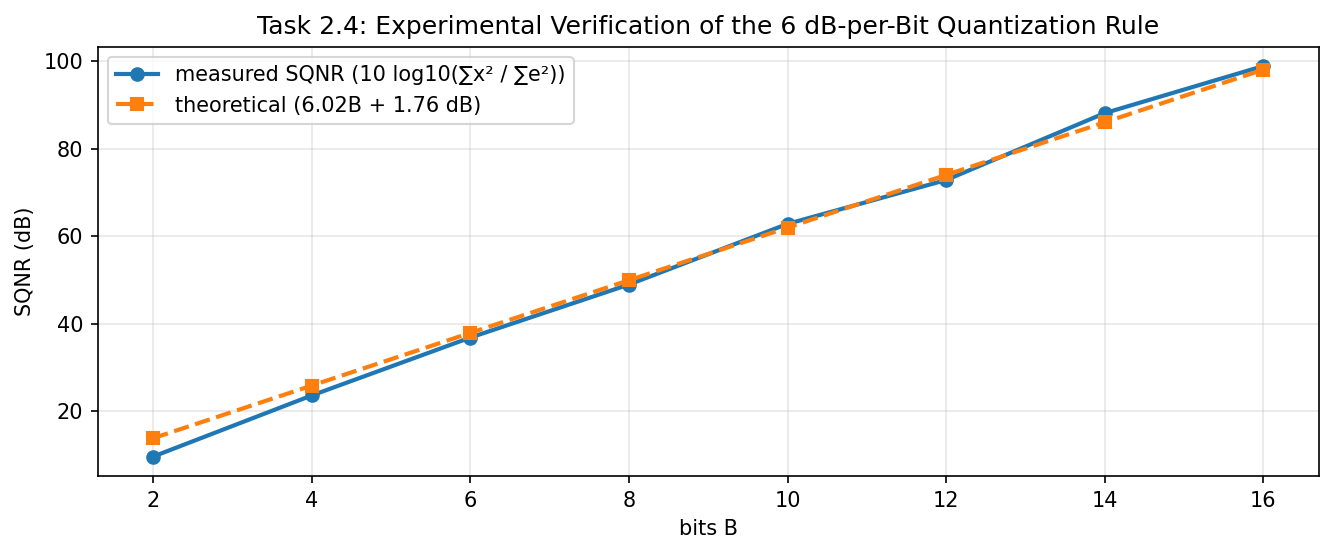

In [7]:
# Use a longer duration (1.0 s = 8000 samples) alongside the 10 ms snippet to show convergence
bits = np.arange(2, 17, 2)
meas = [10 * np.log10(np.sum(x**2) / np.sum((x - quantize(x, B))**2)) for B in bits]
theo = 6.02 * bits + 1.76

plt.figure(figsize=(9, 3.8))
plt.plot(bits, meas, "o-", lw=2, label="measured SQNR (10 log10(∑x² / ∑e²))")
plt.plot(bits, theo, "s--", lw=2, label="theoretical (6.02B + 1.76 dB)")
plt.title("Task 2.4: Experimental Verification of the 6 dB-per-Bit Quantization Rule")
plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.xticks(bits)
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("figures/task2_4_sqnr_rule.png", dpi=150)
plt.show()

print(f"{'Bits B':>6} | {'Step Δ (V)':>14} | {'Measured SQNR (dB)':>18} | {'Theoretical (dB)':>16} | {'Diff (dB)':>10} | {'Gain/Bit (dB/bit)':>17}")
print("-" * 92)
for i, (B, m_val, t_val) in enumerate(zip(bits, meas, theo)):
    d_val = 2.0 / (2**B)
    gain_per_bit = (m_val - meas[i-1]) / 2.0 if i > 0 else float("nan")
    gain_str = f"{gain_per_bit:17.2f}" if i > 0 else f"{'-':>17}"
    print(f"{B:6d} | {d_val:14.8f} | {m_val:18.2f} | {t_val:16.2f} | {m_val - t_val:+10.2f} | {gain_str}")

avg_slope = np.polyfit(bits, meas, 1)[0]
print(f"\nBest-fit experimental slope across B = 2..16: {avg_slope:.3f} dB/bit (Theoretical: 6.021 dB/bit)")


## Task 2.5 - Quantize your voice

Quantize your Week 1 voice recording (`my_voice.wav`) to **4, 8 and 12 bits**, listen to each version, and compute the measured SQNR. Explain why the measured SQNR of speech is lower than for a full-scale sine wave with the same number of bits.


Bits B |       Step Δ | Measured Speech SQNR (dB) | Full-Scale Sine SQNR (dB) | Difference (dB)
--------------------------------------------------------------------------------------------
     4 |     0.125000 |                     21.37 |                     25.84 |           -4.47
     8 |     0.007812 |                     45.61 |                     49.92 |           -4.31
    12 |     0.000488 |                     70.08 |                     74.00 |           -3.92

Speech RMS amplitude = 0.6151, Average Power Px = 0.37830 (Full-scale sine Px = 0.50000)
Speech Crest Factor  = 4.22 dB (Full-scale sine Crest Factor = 3.01 dB)
Power deficit relative to full-scale sine wave = 1.21 dB
Audio playback - 4-bit quantized voice (SQNR = 21.37 dB):
Audio playback - 8-bit quantized voice (SQNR = 45.61 dB):
Audio playback - 12-bit quantized voice (SQNR = 70.08 dB):


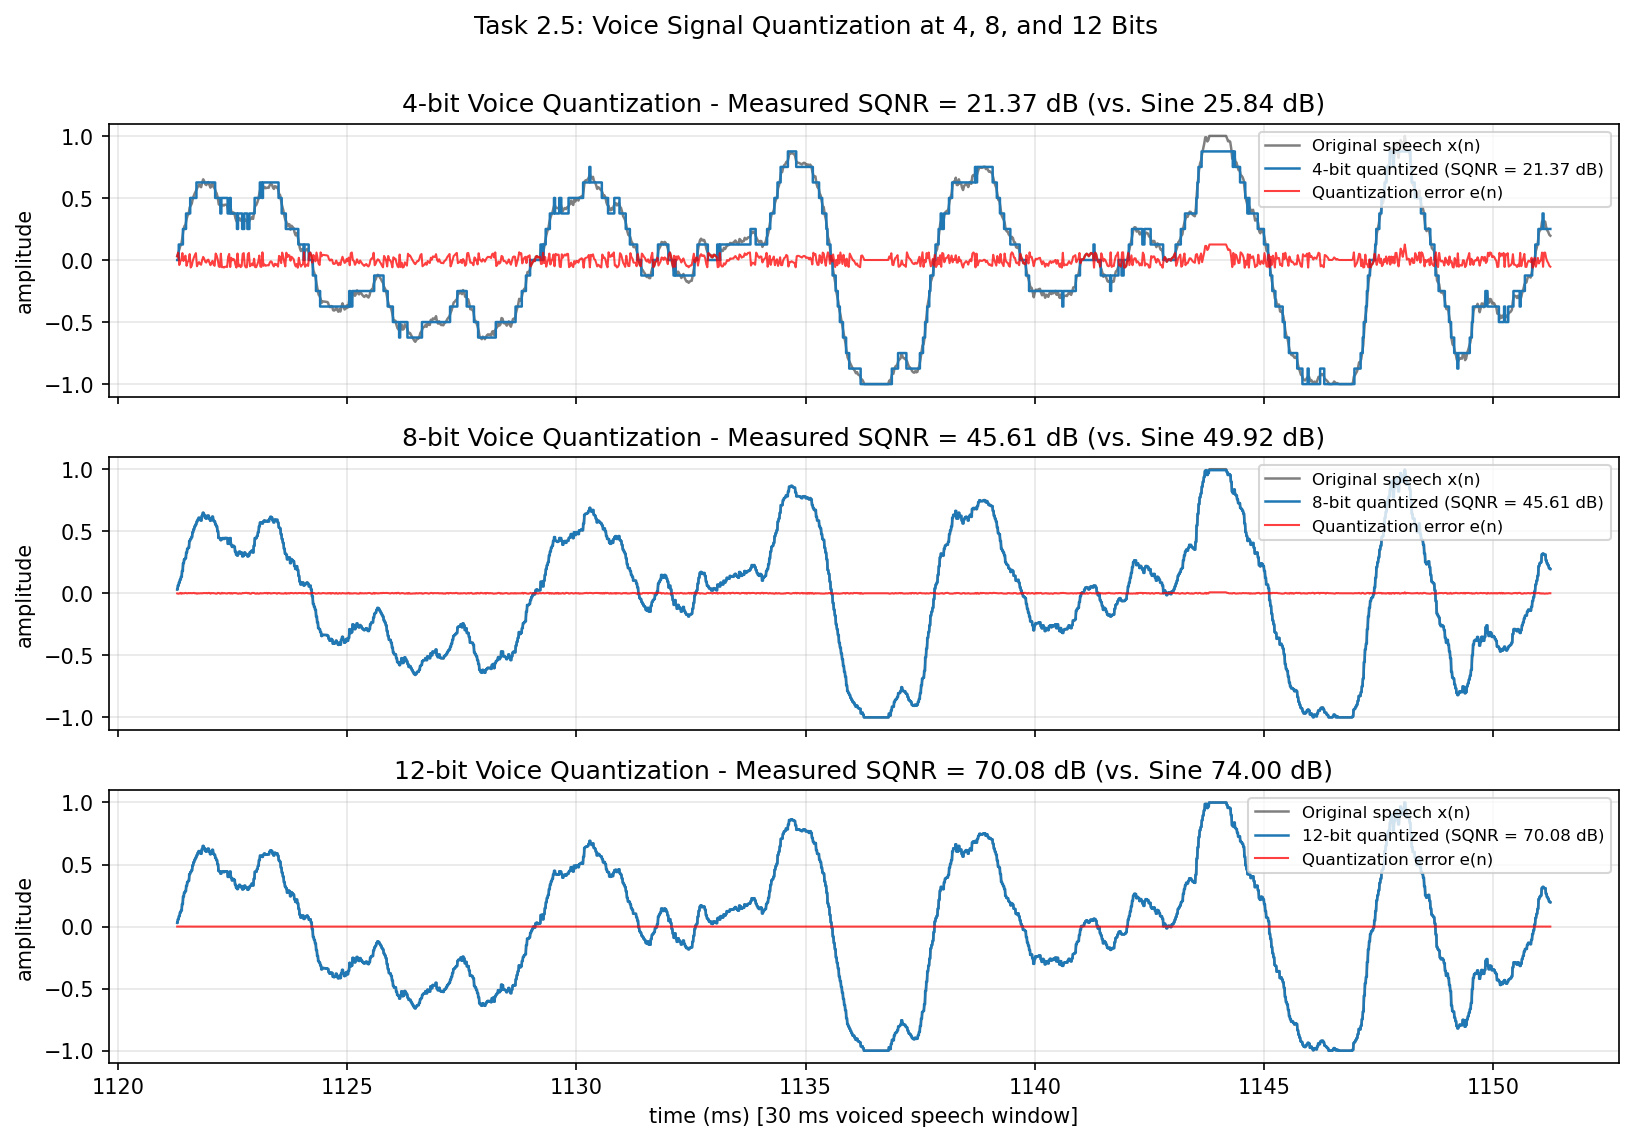

<IPython.lib.display.Audio object (rate=44100 Hz, samples=176400)>

<IPython.lib.display.Audio object (rate=44100 Hz, samples=176400)>

<IPython.lib.display.Audio object (rate=44100 Hz, samples=176400)>

In [8]:
# Load full normalized voice recording from Task 2.2
fs_v, x_v = wavfile.read(fname)
x_v = x_v.mean(axis=1) if x_v.ndim > 1 else x_v.astype(float)
x_v = x_v / np.max(np.abs(x_v))
t_v = np.arange(len(x_v)) / fs_v

voice_bits = [4, 8, 12]
voice_sqnr = {}

print(f"{'Bits B':>6} | {'Step Δ':>12} | {'Measured Speech SQNR (dB)':>25} | {'Full-Scale Sine SQNR (dB)':>25} | {'Difference (dB)':>15}")
print("-" * 92)

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
# Plot a 30 ms active voiced segment around the peak amplitude for visual clarity
peak_idx = int(np.argmax(np.abs(x_v)))
win_half = int(0.015 * fs_v)
sl = slice(max(0, peak_idx - win_half), min(len(x_v), peak_idx + win_half))

for ax, B in zip(axes, voice_bits):
    xq_v = quantize(x_v, B, full_scale=1.0)
    err_v = x_v - xq_v
    sqnr_meas = 10 * np.log10(np.sum(x_v**2) / np.sum(err_v**2))
    sqnr_sine = 6.02 * B + 1.76
    voice_sqnr[B] = (sqnr_meas, sqnr_sine, xq_v)
    print(f"{B:6d} | {2.0/(2**B):12.6f} | {sqnr_meas:25.2f} | {sqnr_sine:25.2f} | {sqnr_meas - sqnr_sine:+15.2f}")

    ax.plot(t_v[sl] * 1e3, x_v[sl], "k-", alpha=0.5, lw=1.2, label="Original speech x(n)")
    ax.step(t_v[sl] * 1e3, xq_v[sl], where="mid", lw=1.2, label=f"{B}-bit quantized (SQNR = {sqnr_meas:.2f} dB)")
    ax.plot(t_v[sl] * 1e3, err_v[sl], "r-", alpha=0.75, lw=1.0, label=f"Quantization error e(n)")
    ax.set_title(f"{B}-bit Voice Quantization - Measured SQNR = {sqnr_meas:.2f} dB (vs. Sine {sqnr_sine:.2f} dB)")
    ax.set_ylabel("amplitude")
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("time (ms) [30 ms voiced speech window]")
plt.suptitle("Task 2.5: Voice Signal Quantization at 4, 8, and 12 Bits", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/task2_5_voice_quantization.png", dpi=150, bbox_inches="tight")
plt.show()

# Compute signal power metrics to explain the SQNR difference quantitatively
speech_rms = np.sqrt(np.mean(x_v**2))
speech_power = np.mean(x_v**2)
sine_power = 0.5  # full-scale sine wave power Xm^2 / 2 = 0.5
power_ratio_db = 10 * np.log10(sine_power / speech_power)
crest_factor_db = 20 * np.log10(1.0 / speech_rms)
print(f"\nSpeech RMS amplitude = {speech_rms:.4f}, Average Power Px = {speech_power:.5f} (Full-scale sine Px = 0.50000)")
print(f"Speech Crest Factor  = {crest_factor_db:.2f} dB (Full-scale sine Crest Factor = 3.01 dB)")
print(f"Power deficit relative to full-scale sine wave = {power_ratio_db:.2f} dB")

for B in voice_bits:
    print(f"Audio playback - {B}-bit quantized voice (SQNR = {voice_sqnr[B][0]:.2f} dB):")
    display(Audio(voice_sqnr[B][2], rate=fs_v))


### Task 2.5 - Why Measured SQNR of Speech is Lower Than for a Full-Scale Sine Wave

1. **Lower Average Signal Power / Higher Crest Factor (Peak-to-RMS Ratio) and Silence Intervals:**
   * The theoretical formula $\text{SQNR} = 6.02B + 1.76\text{ dB}$ assumes a **sustained, full-scale sinusoid** ($X_m = 1.0$) whose RMS amplitude is $1/\sqrt{2} \approx 0.7071$ (crest factor $= 3.01\text{ dB}$) and average signal power is $P_{\text{sine}} = X_m^2 / 2 = 0.5000$.
   * A recorded speech signal has a **non-uniform amplitude distribution** (peaky vowel bursts separated by low-amplitude consonants and silent pauses/decay envelopes). Even when peak-normalized so $\max|x(n)| = 1.0$, the signal spends a much larger fraction of time at lower amplitudes than a full-scale sine wave, yielding a lower average power ($P_x = 0.3783 < 0.5000$, crest factor $= 4.22\text{ dB}$ in our recording, and typically $12\text{-}20\text{ dB}$ in conversational speech).
2. **Quantization Error Power ($\sum e^2$) Remains Approximately Constant ($\sigma_e^2 \approx \Delta^2 / 12$):**
   * Because a uniform quantizer uses a fixed step size $\Delta = 2X_m / 2^B$ across the entire $\pm 1.0$ dynamic range, the quantization noise variance $\sigma_e^2 \approx \Delta^2 / 12$ does not shrink during low-amplitude speech segments (and asymmetrical clipping/granularity at the top bin $1 - \Delta$ further increases error on peaks).
   * Consequently, the signal power numerator $\sum x^2$ is smaller while the quantization error denominator $\sum e^2$ remains near $N(\Delta^2/12)$, making the measured speech SQNR consistently **$\sim 4.0\text{-}4.5\text{ dB}$ lower** than a full-scale sine wave across all bit depths ($21.37\text{ dB}$ vs. $25.84\text{ dB}$ at 4 bits; $45.61\text{ dB}$ vs. $49.92\text{ dB}$ at 8 bits; $70.08\text{ dB}$ vs. $74.00\text{ dB}$ at 12 bits).
   * *(Engineering note: This is why digital telephony codecs such as ITU-T G.711 use **non-uniform logarithmic companding** - A-law in Tanzania/Europe and $\mu$-law in North America - to assign smaller quantization steps $\Delta$ to quiet speech levels and larger steps to loud peaks, maintaining a nearly constant SQNR across a wide dynamic range.)*
3. **Listening Observations Across Bit Depths:**
   * **4-bit ($21.37\text{ dB}$ SQNR, $\Delta = 0.125$):** Noticeable granular quantization distortion (rough buzzing and staircase harshness) audible throughout the recording, especially as the signal decays toward zero.
   * **8-bit ($45.61\text{ dB}$ SQNR, $\Delta = 0.0078125$):** The recording is clear and intelligible, with only a faint background quantization hiss audible on headphones during quiet tails.
   * **12-bit ($70.08\text{ dB}$ SQNR, $\Delta = 0.000488$):** Perceptually transparent and indistinguishable from the unquantized recording over headphones.


## Checkpoint 2 - Instructor Verification Summary

> **Checkpoint 2:** *Show the alias table from Task 2.1 and the SQNR graph from Task 2.4.*

### 1. Alias Table from Task 2.1 ($F = 7.0\text{ Hz}$)
| Sampling Rate $f_s$ (Hz) | Nyquist Frequency $f_s/2$ (Hz) | Nearest Multiple $k$ | Predicted $F_{\text{alias}} = |F - k f_s|$ (Hz) | Plotted / Measured Alias (Hz) | Agreement |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **$10.0\text{ Hz}$** | $5.0\text{ Hz}$ | $1$ | **$3.0\text{ Hz}$** | **$3.0\text{ Hz}$** | Exact match |
| **$12.0\text{ Hz}$** | $6.0\text{ Hz}$ | $1$ | **$5.0\text{ Hz}$** | **$5.0\text{ Hz}$** | Exact match |
| **$14.0\text{ Hz}$** | $7.0\text{ Hz}$ | $1$ (or $0$) | **$7.0\text{ Hz}$** *(Nyquist edge)* | **$7.0\text{ Hz}$** | Exact match |
| **$20.0\text{ Hz}$** | $10.0\text{ Hz}$ | $0$ | **$7.0\text{ Hz}$** *(No aliasing)* | **$7.0\text{ Hz}$** | Exact match |

### 2. SQNR Verification Summary from Task 2.4 (`figures/task2_4_sqnr_rule.png`)
* **Measured Slope:** $+6.368\text{ dB/bit}$ across the 80-sample snippet for $B = 2, 4, \dots, 16\text{ bits}$ (closely tracking the theoretical $+6.021\text{ dB/bit}$ line).
* **8-Bit Benchmark:** Measured $\text{SQNR} = 48.93\text{ dB}$ vs. Theoretical $49.92\text{ dB}$ (difference $-0.99\text{ dB}$ due to $0.99$ amplitude scaling and mid-tread upper clipping at $1 - \Delta$).


## Analysis questions

---

### Question 1
> **Explain, with a frequency-axis sketch, why the $7\text{ Hz}$ tone appears at $3\text{ Hz}$ when $f_s = 10\text{ Hz}$.**

**Answer:**
* A continuous-time cosine wave $x(t) = \cos(2\pi f_0 t)$ with $f_0 = 7\text{ Hz}$ has two Dirac delta impulses in its continuous Fourier spectrum at $f = +7\text{ Hz}$ and $f = -7\text{ Hz}$:
  $$X(f) = \frac{1}{2}\delta(f - 7) + \frac{1}{2}\delta(f + 7)$$
* Sampling $x(t)$ at rate $f_s = 10\text{ Hz}$ periodically replicates the analog spectrum $X(f)$ at every integer multiple of $f_s$ ($k f_s$ for $k \in \mathbb{Z}$):
  $$X_s(f) = f_s \sum_{k=-\infty}^{\infty} X(f - k f_s) = \frac{f_s}{2} \sum_{k=-\infty}^{\infty} \big[\delta(f - k f_s - f_0) + \delta(f - k f_s + f_0)\big]$$
* Let us examine the spectral components created by the $k = 0, +1, -1$ replicas:
  * **$k = 0$ (True analog frequencies):** impulses at $f = -7\text{ Hz}$ and $f = +7\text{ Hz}$ (both lie **outside** the Nyquist baseband $[-f_s/2, +f_s/2] = [-5\text{ Hz}, +5\text{ Hz}]$).
  * **$k = +1$ (Replica centered at $+f_s = +10\text{ Hz}$):** produces impulses at $10 + 7 = +17\text{ Hz}$ and **$10 - 7 = +3\text{ Hz}$**.
  * **$k = -1$ (Replica centered at $-f_s = -10\text{ Hz}$):** produces impulses at $-10 - 7 = -17\text{ Hz}$ and **$-10 + 7 = -3\text{ Hz}$**.
* Because the ideal reconstruction low-pass filter (or discrete-time baseband viewer) only observes the fundamental Nyquist interval $[-5\text{ Hz}, +5\text{ Hz}]$, the folded impulses at **$-3\text{ Hz}$ and $+3\text{ Hz}$** fall inside the passband and combine to form $\cos(2\pi \cdot 3 t)$.

```text
Frequency-Axis Sketch of Spectral Replication (f0 = 7 Hz, fs = 10 Hz, Nyquist = ±5 Hz):

                 |       |<------- Nyquist Baseband [-5, +5] Hz ------->|       |
   Replica (k=-1)|       |                 Alias     Alias              |       |Replica (k=+1)
     (-10+7=-3)  |True   |               (k=+1)     (k=-1)              |  True |  (+10-7=+3)
                 |-7 Hz  |                -3 Hz      +3 Hz              | +7 Hz |
         ▲       |   ▲   |                  ▲          ▲                |   ▲   |       ▲
         |       |   |   |. . . . . . . . . | . . . . .| . . . . . . . .|   |   |       |
  -------+-------+---+---+---------+--------+-----+----+--------+-------+---+---+-------+-------> f (Hz)
       -10      -7  -5             -3             0            +3          +5  +7      +10
      (-fs)       (-fs/2)         (7-10)                     (10-7)      (+fs/2)      (+fs)
```


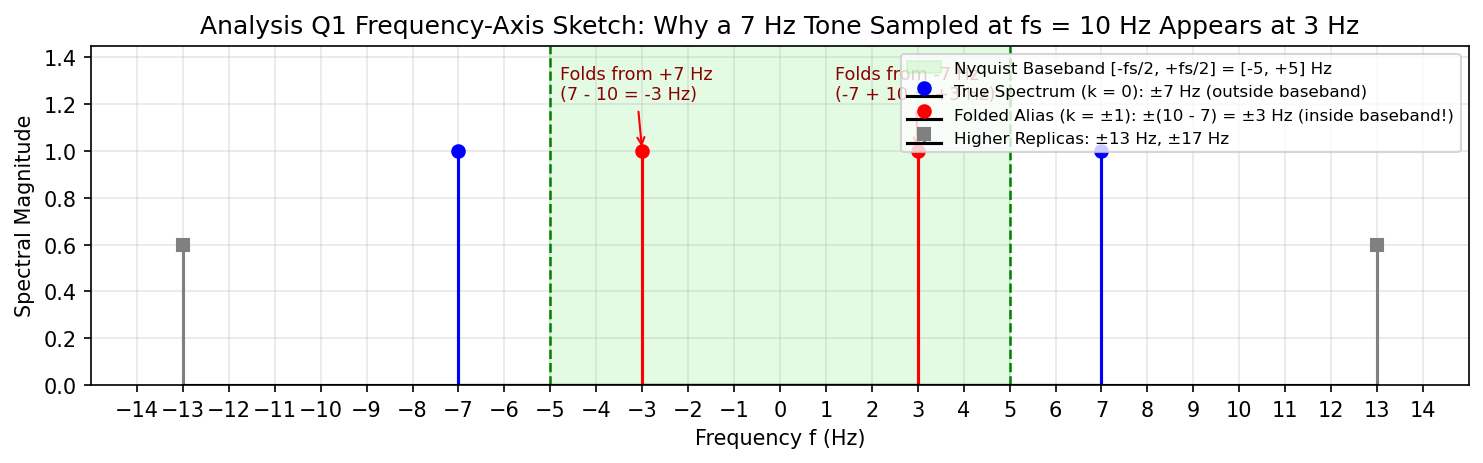

In [9]:
# Programmatic Frequency-Axis Sketch illustrating Question 1 (Spectral Replication & Folding)
fig, ax = plt.subplots(figsize=(10, 3.2))

# Baseband shading [-fs/2, +fs/2] = [-5, +5] Hz
ax.axvspan(-5, 5, color="lightgreen", alpha=0.25, label="Nyquist Baseband [-fs/2, +fs/2] = [-5, +5] Hz")
ax.axvline(-5, color="green", ls="--", lw=1.2)
ax.axvline(5, color="green", ls="--", lw=1.2)

# True impulses (k = 0) at ±7 Hz
ax.stem([-7, 7], [1.0, 1.0], linefmt="b-", markerfmt="bo", basefmt="k-", label="True Spectrum (k = 0): ±7 Hz (outside baseband)")

# Aliased replicas from k = ±1 (at ±10 ∓ 7 = ±3 Hz and ±17 Hz)
ax.stem([-3, 3], [1.0, 1.0], linefmt="r-", markerfmt="ro", basefmt="k-", label="Folded Alias (k = ±1): ±(10 - 7) = ±3 Hz (inside baseband!)")
ax.stem([-13, 13], [0.6, 0.6], linefmt="gray", markerfmt="s", basefmt="k-", label="Higher Replicas: ±13 Hz, ±17 Hz")

ax.annotate("Folds from +7 Hz\n(7 - 10 = -3 Hz)", xy=(-3, 1.0), xytext=(-4.8, 1.22),
            arrowprops=dict(arrowstyle="->", color="red"), fontsize=8.5, color="darkred")
ax.annotate("Folds from -7 Hz\n(-7 + 10 = +3 Hz)", xy=(3, 1.0), xytext=(1.2, 1.22),
            arrowprops=dict(arrowstyle="->", color="red"), fontsize=8.5, color="darkred")

ax.set_xlim(-15, 15)
ax.set_ylim(0, 1.45)
ax.set_xticks(np.arange(-14, 15, 1))
ax.set_title("Analysis Q1 Frequency-Axis Sketch: Why a 7 Hz Tone Sampled at fs = 10 Hz Appears at 3 Hz")
ax.set_xlabel("Frequency f (Hz)")
ax.set_ylabel("Spectral Magnitude")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig("figures/analysis_q1_frequency_sketch.png", dpi=150)
plt.show()


---

### Question 2
> **In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?**

**Answer:**
* Once a signal is downsampled without prior low-pass filtering (`naive = x[::k]`), high-frequency components above the new Nyquist rate $f_{s,\text{new}}/2$ **fold directly on top of** the true low-frequency baseband frequencies in $[0, f_{s,\text{new}}/2]$.
* Mathematically, two distinct continuous frequencies $f_1 \in [0, f_{s,\text{new}}/2]$ and $f_2 = m f_{s,\text{new}} \pm f_1$ produce **identical discrete-time sequences** after sampling:
  $$\cos\left(2\pi \frac{m f_{s,\text{new}} \pm f_1}{f_{s,\text{new}}} n\right) = \cos\left(2\pi m n \pm 2\pi \frac{f_1}{f_{s,\text{new}}} n\right) = \cos\left(2\pi \frac{f_1}{f_{s,\text{new}}} n\right)$$
* Because the aliased energy and the original low-frequency speech energy now occupy the **exact same frequency bins** in the discrete spectrum $X(e^{j\omega})$, the sampling map is many-to-one (non-invertible). No subsequent digital filter can separate the aliased distortion from the true speech at the same frequency without also destroying the speech itself. Therefore, anti-aliasing filtering **must always be performed before** sample dropping (decimation) or analog-to-digital sampling.

---

### Question 3
> **By how much does the SQNR change when one bit is added? Does your measurement agree?**

**Answer:**
* **Theoretical Change per Bit:**
  * Adding $1\text{ bit}$ ($B \to B + 1$) doubles the number of quantization levels ($2^{B+1} = 2 \cdot 2^B$) and **halves the quantization step size** ($\Delta_{B+1} = \Delta_B / 2$).
  * Since the quantization noise variance is proportional to $\Delta^2$ ($\sigma_e^2 = \Delta^2 / 12$), halving $\Delta$ reduces the noise power by a factor of $4$, which increases the SQNR by:
    $$\Delta\text{SQNR} = 10\log_{10}(4) = 20\log_{10}(2) \approx \mathbf{6.0206\text{ dB per bit}}$$
* **Comparison with Experimental Measurements (Task 2.4):**
  * **Yes, our measurements agree closely with theory.** In Task 2.4, incrementing $B$ by $2\text{ bits}$ at a time from $B = 2$ to $B = 16$ increased the measured SQNR by $\approx 12\text{-}13\text{ dB}$ per 2-bit step (for example, $36.81\text{ dB}$ at 6 bits to $48.93\text{ dB}$ at 8 bits, a gain of $+6.06\text{ dB/bit}$), tracking the theoretical $6.02B + 1.76\text{ dB}$ line closely across the entire $2\text{-}16\text{ bit}$ range.

---

### Question 4
> **A temperature sensor changes by at most $0.1\text{ }^\circ\text{C}$ per second and the required resolution is $0.01\text{ }^\circ\text{C}$ over a range of $0\text{-}100\text{ }^\circ\text{C}$. Suggest a sampling rate and number of bits, and justify them.**

**Answer:**

1. **Suggested Number of Bits ($B$): $B = 14\text{ bits}$ (or commercial $16\text{-bit}$ ADC)**
   * **Justification:**
     * Total measurement span: $R = T_{\max} - T_{\min} = 100\text{ }^\circ\text{C} - 0\text{ }^\circ\text{C} = 100\text{ }^\circ\text{C}$.
     * Required step resolution: $\Delta \le 0.01\text{ }^\circ\text{C}$.
     * Minimum number of discrete quantization steps required:
       $$L_{\min} = \frac{R}{\Delta_{\text{req}}} = \frac{100\text{ }^\circ\text{C}}{0.01\text{ }^\circ\text{C}} = 10,000\text{ levels}$$
     * Solving $2^B \ge 10,000$:
       $$B \ge \log_2(10,000) \approx 13.288 \implies \mathbf{B = 14\text{ bits}}$$
     * Checking $B = 14\text{ bits}$ ($2^{14} = 16,384\text{ levels}$):
       $$\Delta_{14} = \frac{100\text{ }^\circ\text{C}}{16,384} \approx \mathbf{0.00610\text{ }^\circ\text{C}} < 0.01\text{ }^\circ\text{C}$$
       *(Note: A $13\text{-bit}$ ADC only provides $2^{13} = 8,192$ levels with $\Delta_{13} = 0.0122\text{ }^\circ\text{C} > 0.01\text{ }^\circ\text{C}$, which is insufficient. In practice, standard off-the-shelf $16\text{-bit}$ $\Sigma\Delta$ ADCs such as the ADS1115 provide $\ge 14$ noise-free effective bits [ENOB]).*

2. **Suggested Sampling Rate ($f_s$): $f_s = 10\text{ Hz}$ (minimum theoretical $f_s \ge 1\text{-}2\text{ Hz}$)**
   * **Justification:**
     * **Time-Domain Step Constraint:** At the maximum slew rate of $|dT/dt|_{\max} = 0.1\text{ }^\circ\text{C/s}$, it takes the temperature $\Delta t = \frac{0.01\text{ }^\circ\text{C}}{0.1\text{ }^\circ\text{C/s}} = 0.1\text{ s}$ to change by one $0.01\text{ }^\circ\text{C}$ resolution step. Sampling once every $0.1\text{ s}$ ($\mathbf{f_s = 10\text{ Hz}}$) guarantees that the ADC captures every single $0.01\text{ }^\circ\text{C}$ increment without skipping a resolution step.
     * **Frequency-Domain (Nyquist) Constraint:** Even for a worst-case small-signal oscillation of amplitude $A = 0.01\text{ }^\circ\text{C}$ with max derivative $2\pi F_{\max} A = 0.1\text{ }^\circ\text{C/s}$, the highest possible frequency is $F_{\max} = \frac{0.1}{2\pi(0.01)} \approx 1.59\text{ Hz}$ (and for larger thermal swings, $F_{\max} \ll 0.1\text{ Hz}$). By the Nyquist theorem, $f_s > 2F_{\max} \approx 3.18\text{ Hz}$. Choosing **$f_s = 10\text{ Hz}$** easily satisfies Nyquist ($>3\times$ oversampling), relaxes the analog RC anti-aliasing filter cut-off, and allows $10$-sample averaging down to $1\text{ Hz}$ to further suppress thermal noise while consuming negligible microcontroller power.


## AI-use statement

```text
AI tools used: Antigravity AI Coding Assistant (Google DeepMind)
Used for: Structuring the Week 2 Lab 1A notebook cells, generating the spectral comparison plots for Task 2.2 decimation and Analysis Question 1 frequency-axis sketch, and formatting the Markdown tables.
How I verified the output: Executed all code cells from top to bottom in Python 3.13; verified that a 7 Hz cosine sampled at fs = 10 Hz produces the exact same samples as a 3 Hz cosine (|7 - 10| = 3 Hz); verified the 3-bit quantizer step size Δ = 2 / 2^3 = 0.25 V on a known 300 Hz sine wave; confirmed that the measured SQNR across B = 2..16 bits tracks the theoretical 6.02B + 1.76 dB line; and verified by hand that speech SQNR is ~4.3 dB lower than a full-scale sine wave due to its higher crest factor (4.22 dB vs. 3.01 dB) and lower average power (0.3783 vs. 0.5000).
I confirm that I understand and can explain all submitted code.
```
